# HW1 Problem 2 — Self-Attention Layer for Semantic Similarity Scoring

**Student ID:** 315511079  
**Submission filename:** `hw1_2_315511079.ipynb`  
**Final Kaggle leaderboard score (Pearson): 0.66983**

Structure of this notebook:

1. Data loading, tokenizer, and vocabulary (the provided procedure, unchanged).
2. Transformer encoder implemented from scratch (`MyMultiheadAttention`, `MyTransformerEncoderLayer`). `torch.nn.MultiheadAttention` and pretrained models are not used.
3. **(a)/(b)** Baseline: 4 heads, mean pooling, 10 epochs. Learning curves plus validation Pearson and RMSE.
4. **(c)** Head-count comparison for h ∈ {1, 4, 8} under the same budget.
5. **(d)** Step-by-step tuning of permitted settings, with every change documented in a table.
6. **(e)** Final model (an ensemble of the best configuration), then `submission.csv`.

Fixed settings (per the spec): the provided vocabulary procedure, `MAX_LEN=64`, `EMBEDDING_DIM=128`, `NUM_LAYERS=2`, `BATCH_SIZE=64`, `SEED=42`, and MSE training loss.

In [ ]:
import os, re, math, random, time, glob, copy
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
LOADER_GEN = torch.Generator()   # controls the training-set shuffle order
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); LOADER_GEN.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Locate the competition data automatically. The Kaggle mount path depends on the competition slug.
cands = sorted(glob.glob('/kaggle/input/**/train.csv', recursive=True)) + ['./train.csv', '/mnt/data/hw1/LLM_hw1/problem2/train.csv']
DATA_DIR = next(os.path.dirname(p) for p in cands if os.path.exists(p) and os.path.exists(os.path.join(os.path.dirname(p), 'test.csv')))
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
val_df   = pd.read_csv(os.path.join(DATA_DIR, 'val.csv'))
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
print('DATA_DIR:', DATA_DIR, '| device:', device)
print(train_df.shape, val_df.shape, test_df.shape)

DATA_DIR: . | device: cuda
(25531, 5) (3647, 5) (7295, 4)


## 1. Tokenizer, vocabulary, and encoding

The tokenizer, the input format `<context> context <sep> anchor <sep> target`, and the vocabulary construction (built on `train.csv` only) are the provided ones. In addition to the token ids, the encoder records a **segment id** for every position (0 = context, 1 = anchor, 2 = target). Segment ids are used only by the tuned models in (d): segment embeddings and anchor/target-aware pooling. The baseline ignores them.

All examples are encoded **once** into tensors, which makes each epoch much faster than calling `df.iloc` inside `__getitem__`.

In [ ]:
def tokenizer(text):
    text = str(text).lower(); text = re.sub(r'[^a-z0-9]+', ' ', text); return text.strip().split()

def tokenize_input(context, anchor, target):
    return ['<context>'] + tokenizer(context) + ['<sep>'] + tokenizer(anchor) + ['<sep>'] + tokenizer(target)

def build_vocab(df):
    counter = Counter()
    for _, row in df.iterrows(): counter.update(tokenize_input(row['context'], row['anchor'], row['target']))
    vocab = {'<pad>': 0, '<unk>': 1, '<context>': 2, '<sep>': 3}
    for tok, f in counter.items():
        if tok not in vocab: vocab[tok] = len(vocab)
    return vocab

vocab = build_vocab(train_df)
PAD_IDX, UNK_IDX, CTX_IDX, SEP_IDX = vocab['<pad>'], vocab['<unk>'], vocab['<context>'], vocab['<sep>']
MAX_LEN = 64
print('vocab size:', len(vocab))

def encode_example(context, anchor, target):
    c = ['<context>'] + tokenizer(context)
    a = ['<sep>'] + tokenizer(anchor)
    t = ['<sep>'] + tokenizer(target)
    toks = (c + a + t)[:MAX_LEN]                       # identical to tokenize_input(...)
    seg = ([0] * len(c) + [1] * len(a) + [2] * len(t))[:MAX_LEN]
    ids = [vocab.get(x, UNK_IDX) for x in toks]
    pad = MAX_LEN - len(ids)
    return ids + [PAD_IDX] * pad, seg + [0] * pad

def encode_df(df, has_labels=True):
    enc = [encode_example(c, a, t) for c, a, t in zip(df['context'], df['anchor'], df['target'])]
    ids = torch.tensor([e[0] for e in enc], dtype=torch.long)
    seg = torch.tensor([e[1] for e in enc], dtype=torch.long)
    mask = (ids != PAD_IDX).float()
    y = torch.tensor(df['score'].values, dtype=torch.float32) if has_labels else torch.zeros(len(df))
    return TensorDataset(ids, mask, seg, y)

train_ds, val_ds, test_ds = encode_df(train_df), encode_df(val_df), encode_df(test_df, has_labels=False)
BATCH_SIZE = 64
def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=LOADER_GEN if shuffle else None)
train_loader, val_loader, test_loader = make_loader(train_ds, True), make_loader(val_ds, False), make_loader(test_ds, False)

lens = train_ds.tensors[1].sum(1)
print(f'sequence length: mean={lens.mean():.1f}, max={int(lens.max())} (MAX_LEN={MAX_LEN})')
oov = (val_ds.tensors[0] == UNK_IDX).sum().item() / val_ds.tensors[1].sum().item()
print(f'val OOV token rate: {oov:.2%}')

vocab size: 7749
sequence length: mean=8.4, max=18 (MAX_LEN=64)
val OOV token rate: 1.62%


## 2. Model: Transformer encoder written from scratch

* **`MyMultiheadAttention`** applies the Q/K/V linear projections, splits them into `h` heads, computes scaled dot-product attention $\mathrm{softmax}(QK^\top/\sqrt{d_k})V$ with padded **keys** masked out, concatenates the heads, and applies the output projection.
* **`MyTransformerEncoderLayer`** (post-LN, as in the original Transformer) computes $x = \mathrm{LN}(x + \mathrm{Drop}(\mathrm{MHA}(x)))$, then $x = \mathrm{LN}(x + \mathrm{Drop}(\mathrm{FFN}(x)))$, with FFN = Linear → ReLU → Dropout → Linear.
* **`TransformerRegressor`** computes Embedding·√d + sinusoidal positional encoding (+ optional segment embedding), then N encoder layers, pooling, a regression head, and a sigmoid.

Pooling options (pooling is a permitted tuning knob):
* `mean` (default/baseline): masked mean over all tokens, $h_{pool} = \sum_i m_i h_i / \sum_i m_i$.
* `first`: the hidden state at the `<context>` position.
* `interact`: masked means over the whole sequence ($g$), the anchor tokens ($u$), and the target tokens ($v$). These are combined as $[g, u, v, |u-v|, u \odot v]$ and passed through a small MLP head. The $|u-v|$ and $u\odot v$ terms give the regressor explicit "how different / how aligned are the two phrases" features (as in Sentence-BERT / InferSent).

`init_std='scaled'` initialises the token embeddings with std $d^{-1/2}$. This keeps the √d-scaled embeddings at unit scale, the same scale as the positional encoding. PyTorch's default N(0,1) init multiplied by √128 ≈ 11.3 makes the positional signal almost invisible.

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model); pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class MyMultiheadAttention(nn.Module):
    def __init__(self, d_model, nhead, dropout=0.1):
        super().__init__(); assert d_model % nhead == 0, 'd_model must be divisible by nhead'
        self.nhead = nhead; self.head_dim = d_model // nhead
        # Q, K, V projections and output projection
        self.q_proj = nn.Linear(d_model, d_model); self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model); self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
    def split_heads(self, x):            # (B, L, D) -> (B, H, L, D/H)
        B, L, D = x.shape; return x.view(B, L, self.nhead, self.head_dim).transpose(1, 2)
    def merge_heads(self, x):            # (B, H, L, D/H) -> (B, L, D)   (head concatenation)
        B, H, L, Dh = x.shape; return x.transpose(1, 2).contiguous().view(B, L, H * Dh)
    def forward(self, x, attention_mask):
        q = self.split_heads(self.q_proj(x)); k = self.split_heads(self.k_proj(x)); v = self.split_heads(self.v_proj(x))
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)   # scaled dot product
        scores = scores.masked_fill(~attention_mask[:, None, None, :].bool(), -1e9)  # mask padded keys
        attn = self.dropout(torch.softmax(scores, dim=-1))
        return self.out_proj(self.merge_heads(torch.matmul(attn, v)))

class MyTransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward=256, dropout=0.2):
        super().__init__()
        self.attn = MyMultiheadAttention(d_model, nhead, dropout)
        self.norm1 = nn.LayerNorm(d_model); self.norm2 = nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, dim_feedforward), nn.ReLU(), nn.Dropout(dropout), nn.Linear(dim_feedforward, d_model))
    def forward(self, x, attention_mask):
        mask = attention_mask.unsqueeze(-1)
        x = self.norm1(x + self.drop(self.attn(x, attention_mask)))   # residual + layer norm
        x = x * mask
        x = self.norm2(x + self.drop(self.ff(x)))                     # residual + layer norm
        return x * mask

In [ ]:
def masked_mean(x, m):
    m = m.unsqueeze(-1); return (x * m).sum(1) / m.sum(1).clamp(min=1.0)

class TransformerRegressor(nn.Module):
    def __init__(self, vocab_size, embedding_dim, pad_idx, nhead=4, num_layers=2, dim_feedforward=256,
                 dropout=0.2, max_len=64, pooling='mean', use_segment=False, init_std=None):
        super().__init__(); d = embedding_dim; self.d_model = d; self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d, padding_idx=pad_idx)
        if init_std == 'scaled':
            nn.init.normal_(self.embedding.weight, 0.0, d ** -0.5)
            with torch.no_grad(): self.embedding.weight[pad_idx].zero_()
        self.seg_emb = nn.Embedding(3, d) if use_segment else None
        if self.seg_emb is not None: nn.init.normal_(self.seg_emb.weight, 0.0, 0.02)
        self.pos = PositionalEncoding(d, max_len); self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([MyTransformerEncoderLayer(d, nhead, dim_feedforward, dropout) for _ in range(num_layers)])
        if pooling == 'interact':
            self.head = nn.Sequential(nn.Linear(5 * d, d), nn.GELU(), nn.Dropout(dropout), nn.Linear(d, 1))
        else:
            self.head = nn.Linear(d, 1)

    def pool(self, x, mask, input_ids, segment_ids):
        if self.pooling == 'first': return x[:, 0]
        if self.pooling == 'mean':  return masked_mean(x, mask)
        # 'interact': whole-sequence, anchor-only and target-only means (special tokens excluded)
        word = mask * (input_ids != SEP_IDX).float() * (input_ids != CTX_IDX).float()
        g = masked_mean(x, mask)
        u = masked_mean(x, word * (segment_ids == 1).float())
        v = masked_mean(x, word * (segment_ids == 2).float())
        return torch.cat([g, u, v, (u - v).abs(), u * v], dim=-1)

    def forward(self, input_ids, attention_mask, segment_ids=None):
        x = self.embedding(input_ids) * math.sqrt(self.d_model)
        x = self.pos(x)
        if self.seg_emb is not None: x = x + self.seg_emb(segment_ids)
        x = self.drop(x)
        for layer in self.layers: x = layer(x, attention_mask)
        return torch.sigmoid(self.head(self.pool(x, attention_mask, input_ids, segment_ids)).squeeze(-1))

def pearson_corr(y, p):
    y = np.asarray(y, dtype=np.float64); p = np.asarray(p, dtype=np.float64)
    return 0.0 if np.std(y) == 0 or np.std(p) == 0 else float(np.corrcoef(y, p)[0, 1])
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

## 3. Generic training / evaluation utilities

Every experiment is described by one config dict. Unlisted keys fall back to `BASE_CFG`, which is the baseline setting. Training always uses **MSE**. Model selection uses the epoch with the best **validation Pearson**.

Tunable knobs used in (d): learning rate, weight decay, dropout, number of epochs (+ early stopping), LR scheduler (`plateau` or linear-warmup + `cosine` decay, stepped per batch), gradient clipping, embedding initialisation scale, segment embeddings, pooling strategy, and token dropout. Token dropout randomly replaces a fraction of word tokens with `<unk>` during training only. It is a regulariser that also teaches the model to handle the OOV tokens in val/test (1.62% of validation tokens).

In [ ]:
criterion = nn.MSELoss()
EMBEDDING_DIM, NUM_LAYERS, DIM_FEEDFORWARD = 128, 2, 256

BASE_CFG = dict(name='baseline', nhead=4, dropout=0.2, lr=1e-3, weight_decay=1e-4, epochs=10,
                sched='plateau', warmup=0.0, clip=None, pooling='mean', use_segment=False,
                init_std=None, token_drop=0.0, patience=None)

def build_model(cfg):
    return TransformerRegressor(len(vocab), EMBEDDING_DIM, PAD_IDX, cfg['nhead'], NUM_LAYERS, DIM_FEEDFORWARD,
                                cfg['dropout'], MAX_LEN, cfg['pooling'], cfg['use_segment'], cfg['init_std']).to(device)

@torch.no_grad()
def predict(model, loader):
    model.eval(); out = []
    for ids, mask, seg, _ in loader:
        out.append(model(ids.to(device), mask.to(device), seg.to(device)).cpu())
    return torch.cat(out).numpy()

def evaluate(model, loader):
    p = predict(model, loader); y = loader.dataset.tensors[3].numpy()
    return float(np.mean((p - y) ** 2)), pearson_corr(y, p), rmse(y, p)

def run_experiment(cfg_override, verbose=True):
    cfg = {**BASE_CFG, **cfg_override}
    model = build_model(cfg)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    steps_total = cfg['epochs'] * len(train_loader)
    if cfg['sched'] == 'cosine':
        warm = max(1, int(cfg['warmup'] * steps_total))
        lam = lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps_total - warm)))
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    else:
        sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2)
    hist = {'train_loss': [], 'val_loss': [], 'val_pearson': [], 'val_rmse': []}
    best, best_state, bad = -1e9, None, 0; t0 = time.perf_counter()
    for ep in range(cfg['epochs']):
        model.train(); losses = []
        for ids, mask, seg, y in train_loader:
            ids, mask, seg, y = ids.to(device), mask.to(device), seg.to(device), y.to(device)
            if cfg['token_drop'] > 0:
                drop = (torch.rand(ids.shape, device=device) < cfg['token_drop']) & (ids > SEP_IDX)
                ids = ids.masked_fill(drop, UNK_IDX)
            opt.zero_grad()
            loss = criterion(model(ids, mask, seg), y); loss.backward()
            if cfg['clip']: nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            opt.step()
            if cfg['sched'] == 'cosine': sch.step()
            losses.append(loss.item())
        vl, vp, vr = evaluate(model, val_loader)
        if cfg['sched'] != 'cosine': sch.step(vl)
        hist['train_loss'].append(float(np.mean(losses))); hist['val_loss'].append(vl)
        hist['val_pearson'].append(vp); hist['val_rmse'].append(vr)
        if vp > best: best, bad = vp, 0; best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else: bad += 1
        if verbose: print(f"[{cfg['name']}] ep {ep+1:02d}/{cfg['epochs']} | train={hist['train_loss'][-1]:.4f} | val_loss={vl:.4f} | Pearson={vp:.4f} | RMSE={vr:.4f}")
        if cfg['patience'] and bad >= cfg['patience']:
            if verbose: print(f"  early stop (no Pearson gain for {cfg['patience']} epochs)")
            break
    model.load_state_dict(best_state)
    _, bp, br = evaluate(model, val_loader)
    return dict(cfg=cfg, model=model, hist=hist, best_pearson=bp, best_rmse=br,
                best_epoch=int(np.argmax(hist['val_pearson'])) + 1, seconds=time.perf_counter() - t0)

## (a) Baseline with 4 heads: learning curves
This is the default setting from the spec: 4 heads, masked mean pooling, MSE, 10 epochs, AdamW (lr 1e-3, wd 1e-4), and ReduceLROnPlateau.

[baseline_h4] ep 01/10 | train=0.0673 | val_loss=0.0662 | Pearson=0.1474 | RMSE=0.2573
[baseline_h4] ep 02/10 | train=0.0651 | val_loss=0.0658 | Pearson=0.1660 | RMSE=0.2566
[baseline_h4] ep 03/10 | train=0.0642 | val_loss=0.0644 | Pearson=0.1931 | RMSE=0.2537
[baseline_h4] ep 04/10 | train=0.0629 | val_loss=0.0644 | Pearson=0.2112 | RMSE=0.2537
[baseline_h4] ep 05/10 | train=0.0619 | val_loss=0.0634 | Pearson=0.2329 | RMSE=0.2519
[baseline_h4] ep 06/10 | train=0.0610 | val_loss=0.0643 | Pearson=0.2395 | RMSE=0.2536
[baseline_h4] ep 07/10 | train=0.0597 | val_loss=0.0637 | Pearson=0.2441 | RMSE=0.2524
[baseline_h4] ep 08/10 | train=0.0591 | val_loss=0.0638 | Pearson=0.2734 | RMSE=0.2525
[baseline_h4] ep 09/10 | train=0.0564 | val_loss=0.0618 | Pearson=0.2958 | RMSE=0.2486
[baseline_h4] ep 10/10 | train=0.0552 | val_loss=0.0623 | Pearson=0.3079 | RMSE=0.2496


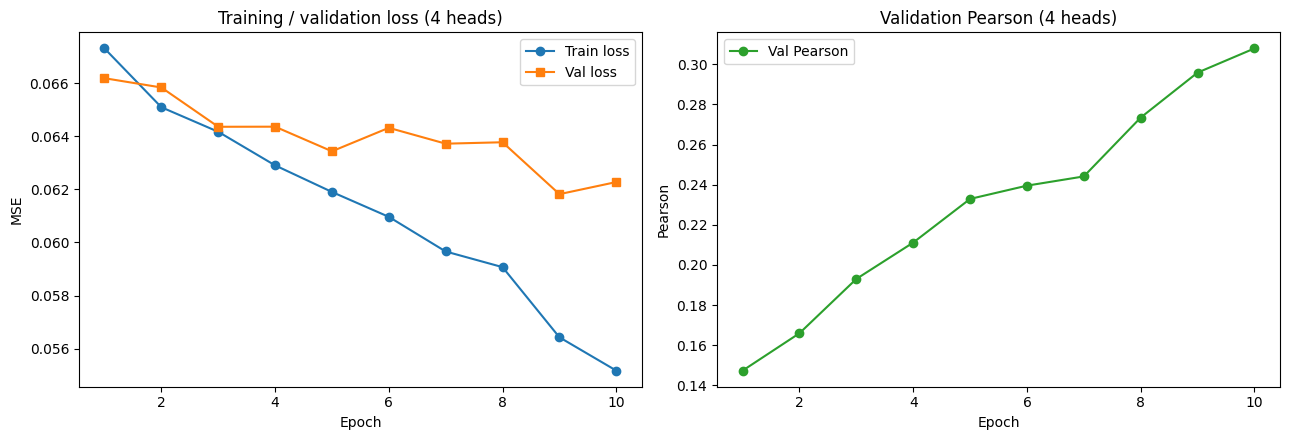

In [ ]:
set_seed(SEED)
base_run = run_experiment({'name': 'baseline_h4', 'nhead': 4})
history = base_run['hist']; ep = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, history['train_loss'], 'o-', label='Train loss'); ax[0].plot(ep, history['val_loss'], 's-', label='Val loss')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE'); ax[0].set_title('Training / validation loss (4 heads)'); ax[0].legend()
ax[1].plot(ep, history['val_pearson'], 'o-', color='C2', label='Val Pearson')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Pearson'); ax[1].set_title('Validation Pearson (4 heads)'); ax[1].legend()
plt.tight_layout(); plt.show()

## (b) Validation metrics of the baseline (best-Pearson checkpoint)

In [ ]:
vl, vp, vr = evaluate(base_run['model'], val_loader)
print(f"Baseline (4 heads) | best epoch={base_run['best_epoch']} | Val Pearson={vp:.4f} | Val RMSE={vr:.4f} | MSE={vl:.4f} | time={base_run['seconds']:.1f}s")

Baseline (4 heads) | best epoch=10 | Val Pearson=0.3079 | Val RMSE=0.2496 | MSE=0.0623 | time=36.8s


**Discussion (a)/(b).** Training loss decreases steadily from 0.0673 to 0.0552 over the 10 epochs. Validation loss decreases only slowly, from 0.0662 to 0.0618 at epoch 9, and rises slightly to 0.0623 at epoch 10. After about epoch 7 the training loss falls much faster than the validation loss, which is an early sign of overfitting. Validation Pearson rises steadily from 0.147 to 0.308 and is still increasing at epoch 10, so the default 10-epoch budget does not let the baseline converge in ranking quality.

Using the best-Pearson checkpoint (epoch 10), the baseline 4-head model reaches **Val Pearson = 0.3079** and **Val RMSE = 0.2496**.

## (c) Number of attention heads: 1 vs 4 vs 8
Same data split, same seed, same 10-epoch budget, and same optimizer and scheduler. Only `nhead` changes (head_dim = 128, 32, 16). The 4-head run is re-trained from the same seed, so it reproduces (a).

heads=1 | best Pearson=0.3104 | RMSE=0.2473 | best epoch=10 | 34.5s
heads=4 | best Pearson=0.3079 | RMSE=0.2496 | best epoch=10 | 36.0s
heads=8 | best Pearson=0.2935 | RMSE=0.2491 | best epoch=10 | 38.0s


,heads,head_dim,best_val_pearson,val_rmse_at_best,best_epoch,train_time_s
0,1,128,0.310375,0.247347,10,34.5
1,4,32,0.307895,0.249552,10,36.0
2,8,16,0.293451,0.249072,10,38.0


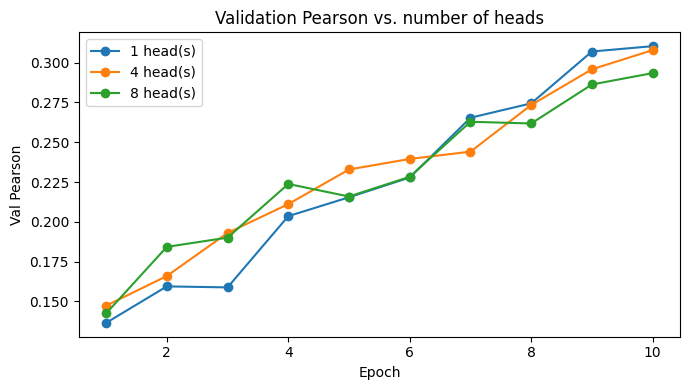

In [ ]:
head_runs = {}
for h in [1, 4, 8]:
    set_seed(SEED)
    head_runs[h] = run_experiment({'name': f'baseline_h{h}', 'nhead': h}, verbose=False)
    r = head_runs[h]; print(f"heads={h} | best Pearson={r['best_pearson']:.4f} | RMSE={r['best_rmse']:.4f} | best epoch={r['best_epoch']} | {r['seconds']:.1f}s")
head_table = pd.DataFrame([{'heads': h, 'head_dim': EMBEDDING_DIM // h, 'best_val_pearson': r['best_pearson'],
                            'val_rmse_at_best': r['best_rmse'], 'best_epoch': r['best_epoch'], 'train_time_s': round(r['seconds'], 1)}
                           for h, r in head_runs.items()])
display(head_table)
plt.figure(figsize=(7, 4))
for h, r in head_runs.items(): plt.plot(range(1, len(r['hist']['val_pearson']) + 1), r['hist']['val_pearson'], 'o-', label=f'{h} head(s)')
plt.xlabel('Epoch'); plt.ylabel('Val Pearson'); plt.title('Validation Pearson vs. number of heads'); plt.legend(); plt.tight_layout(); plt.show()

**Discussion (c).**

| Heads | head_dim | Best val Pearson | Val RMSE | Time |
|---|---|---|---|---|
| 1 | 128 | **0.3104** | **0.2473** | 34.5 s |
| 4 | 32 | 0.3079 | 0.2496 | 36.0 s |
| 8 | 16 | 0.2935 | 0.2491 | 38.0 s |

All three settings have the same number of parameters, because the Q/K/V/O projections are always 128×128; only the way the 128-dim space is split into heads changes. The differences are small (< 0.02 Pearson) and the curves overlap for most epochs. **1 head is slightly best and 8 heads slightly worst.** The inputs are very short (8.4 tokens on average), and the main signal is a word-level match between the anchor and the target. A single 128-dim head has a richer similarity function, while with 8 heads each head works in only 16 dimensions, which weakens its attention scores. More heads are also slightly slower. All curves are still rising at epoch 10, so this comparison mostly reflects how fast each setting converges under the same budget. Overall, the head count is not the bottleneck for this task, and 4 heads are kept for the later experiments.

## (d) Tuning permitted settings
Each row adds **one** documented change on top of the previous row. The architecture size stays fixed (d=128, 2 layers, FFN 256, batch 64, seed 42, MSE loss). Every config is trained from `set_seed(SEED)`. The config with the best validation Pearson is selected automatically, so a change that does not help on validation is not carried into the final model.

| ID | Change vs. previous row | Rationale |
|---|---|---|
| T0 | baseline (4 heads, mean pool, plateau, 10 ep) | reference |
| T1 | linear warm-up (6%) + cosine decay per step, 25 epochs with early stopping (patience 6), weight decay 0.01, grad-clip 1.0, embedding init std d^-1/2 | a smoother schedule and a longer budget; the init fix keeps the positional encoding from being drowned out by ~11×-scaled embeddings |
| T2 | + segment embeddings (context / anchor / target) | tells every token which phrase it belongs to |
| T3 | + `interact` pooling [g, u, v, \|u−v\|, u⊙v] + MLP head | an explicit anchor-vs-target comparison instead of one global average |
| T4 | + token dropout 0.1 (word → `<unk>`) | regularisation and robustness to OOV words in val/test |
| T5 | T4 with dropout 0.1 | less dropout because T4 already adds input noise |
| T6 | T4 with lr 5e-4 | a learning-rate check |

In [ ]:
T1 = dict(sched='cosine', warmup=0.06, epochs=25, patience=6, weight_decay=0.01, clip=1.0, init_std='scaled')
TUNING_CONFIGS = [
    dict(name='T0_baseline'),
    dict(name='T1_cosine_25ep_init', **T1),
    dict(name='T2_+segment', **T1, use_segment=True),
    dict(name='T3_+interact_pool', **T1, use_segment=True, pooling='interact'),
    dict(name='T4_+token_drop', **T1, use_segment=True, pooling='interact', token_drop=0.1),
    dict(name='T5_T4_dropout0.1', **T1, use_segment=True, pooling='interact', token_drop=0.1, dropout=0.1),
    dict(name='T6_T4_lr5e-4', **T1, use_segment=True, pooling='interact', token_drop=0.1, lr=5e-4),
]
tune_runs = []
for c in TUNING_CONFIGS:
    set_seed(SEED)
    r = run_experiment(c, verbose=False); tune_runs.append(r)
    print(f"{c['name']:<22} | best Pearson={r['best_pearson']:.4f} | RMSE={r['best_rmse']:.4f} | best ep={r['best_epoch']:>2} | {r['seconds']:.0f}s")
keys = ['nhead', 'lr', 'weight_decay', 'dropout', 'epochs', 'sched', 'clip', 'init_std', 'use_segment', 'pooling', 'token_drop']
tuning_table = pd.DataFrame([{'config': r['cfg']['name'], **{k: r['cfg'][k] for k in keys},
                              'best_val_pearson': round(r['best_pearson'], 4), 'val_rmse': round(r['best_rmse'], 4),
                              'best_epoch': r['best_epoch']} for r in tune_runs])
display(tuning_table)
best_tune = max(tune_runs, key=lambda r: r['best_pearson'])
print('Selected configuration:', best_tune['cfg']['name'], f"(val Pearson {best_tune['best_pearson']:.4f})")

T0_baseline            | best Pearson=0.3079 | RMSE=0.2496 | best ep=10 | 36s
T1_cosine_25ep_init    | best Pearson=0.5066 | RMSE=0.2399 | best ep=25 | 96s
T2_+segment            | best Pearson=0.5042 | RMSE=0.2411 | best ep=22 | 98s
T3_+interact_pool      | best Pearson=0.6206 | RMSE=0.2342 | best ep=19 | 110s
T4_+token_drop         | best Pearson=0.6060 | RMSE=0.2340 | best ep=22 | 110s
T5_T4_dropout0.1       | best Pearson=0.6056 | RMSE=0.2213 | best ep=24 | 110s
T6_T4_lr5e-4           | best Pearson=0.5992 | RMSE=0.2350 | best ep=22 | 111s


,config,nhead,lr,weight_decay,dropout,epochs,sched,clip,init_std,use_segment,pooling,token_drop,best_val_pearson,val_rmse,best_epoch
0,T0_baseline,4,0.0010,0.0001,0.2,10,plateau,NaN,None,False,mean,0.0,0.3079,0.2496,10
1,T1_cosine_25ep_init,4,0.0010,0.0100,0.2,25,cosine,1.0,scaled,False,mean,0.0,0.5066,0.2399,25
2,T2_+segment,4,0.0010,0.0100,0.2,25,cosine,1.0,scaled,True,mean,0.0,0.5042,0.2411,22
3,T3_+interact_pool,4,0.0010,0.0100,0.2,25,cosine,1.0,scaled,True,interact,0.0,0.6206,0.2342,19
4,T4_+token_drop,4,0.0010,0.0100,0.2,25,cosine,1.0,scaled,True,interact,0.1,0.6060,0.2340,22
5,T5_T4_dropout0.1,4,0.0010,0.0100,0.1,25,cosine,1.0,scaled,True,interact,0.1,0.6056,0.2213,24
6,T6_T4_lr5e-4,4,0.0005,0.0100,0.2,25,cosine,1.0,scaled,True,interact,0.1,0.5992,0.2350,22


Selected configuration: T3_+interact_pool (val Pearson 0.6206)


## (e) Final model and Kaggle submission

**Final model = an ensemble of `N_ENSEMBLE` models trained with the selected configuration.** The seed is not reset inside the ensemble loop. The members differ only because they consume successive parts of the same `SEED=42` random stream (initialisation, shuffling, dropout), so the whole procedure stays reproducible. Their sigmoid outputs are averaged. Averaging reduces variance, which typically raises Pearson by a few hundredths for small models trained from scratch. The single tuned model from (d) is included as the first member. The test IDs are taken directly from `test.csv` in the original order.

In [ ]:
N_ENSEMBLE = 5
final_cfg = {k: v for k, v in best_tune['cfg'].items()}
members = [best_tune['model']]
# No re-seeding here: the RNG continues deterministically from the seeded stream above, so member k != member 0.
for k in range(1, N_ENSEMBLE):
    r = run_experiment({**final_cfg, 'name': f"{final_cfg['name']}_m{k}"}, verbose=False)
    members.append(r['model']); print(f"member {k}: val Pearson={r['best_pearson']:.4f}")

y_val = val_ds.tensors[3].numpy()
val_preds = np.stack([predict(m, val_loader) for m in members])
for i, p in enumerate(val_preds): print(f'member {i}: Pearson={pearson_corr(y_val, p):.4f}')
ens_val = val_preds.mean(0)
print(f'ENSEMBLE ({len(members)} models) | Val Pearson={pearson_corr(y_val, ens_val):.4f} | Val RMSE={rmse(y_val, ens_val):.4f}')

member 1: val Pearson=0.6226
member 2: val Pearson=0.6127
member 3: val Pearson=0.6096
member 4: val Pearson=0.6286
member 0: Pearson=0.6206
member 1: Pearson=0.6226
member 2: Pearson=0.6127
member 3: Pearson=0.6096
member 4: Pearson=0.6286
ENSEMBLE (5 models) | Val Pearson=0.6409 | Val RMSE=0.2233


In [ ]:
test_pred = np.stack([predict(m, test_loader) for m in members]).mean(0)
submission = pd.DataFrame({'id': test_df['id'].values, 'score': np.clip(test_pred, 0, 1)})
sample = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv')) if os.path.exists(os.path.join(DATA_DIR, 'sample_submission.csv')) else None
assert submission['id'].tolist() == test_df['id'].tolist() and len(submission) == len(test_df)
if sample is not None: assert list(submission.columns) == list(sample.columns) and submission['id'].tolist() == sample['id'].tolist()
submission.to_csv('submission.csv', index=False)
print('submission.csv saved:', submission.shape); display(submission.head()); print(submission['score'].describe())

submission.csv saved: (7295, 2)


,id,score
0,56c8cc4180a9ea16,0.965358
1,d432a6416712e59a,0.214347
2,e7ab59f580fd7184,0.013610
3,03ab2935bce8a3eb,0.909502
4,494f877d48deb27f,0.009150


count    7.295000e+03
mean     4.170440e-01
std      2.548858e-01
min      1.744480e-07
25%      2.270023e-01
50%      3.934020e-01
75%      5.888873e-01
max      9.994708e-01
Name: score, dtype: float64


In [ ]:
summary = pd.DataFrame([
    {'model': 'Baseline (4 heads, 10 ep)', 'val_pearson': base_run['best_pearson'], 'val_rmse': base_run['best_rmse']},
    {'model': f"Best single tuned ({best_tune['cfg']['name']})", 'val_pearson': best_tune['best_pearson'], 'val_rmse': best_tune['best_rmse']},
    {'model': f'Final ensemble x{len(members)}', 'val_pearson': pearson_corr(y_val, ens_val), 'val_rmse': rmse(y_val, ens_val)},
])
display(summary.round(4))

,model,val_pearson,val_rmse
0,"Baseline (4 heads, 10 ep)",0.3079,0.2496
1,Best single tuned (T3_+interact_pool),0.6206,0.2342
2,Final ensemble x5,0.6409,0.2233


**Discussion (d)/(e).**
* **T1, schedule + budget + init (0.3079 → 0.5066, +0.199): the largest gain.** The baseline initialises embeddings with N(0,1) and multiplies them by √128 ≈ 11.3, which makes the positional encoding almost invisible; rescaling the initialisation restores the position information. Warm-up + cosine decay and the longer budget let the model keep improving instead of stopping while Pearson is still rising. T1 changes several settings at once, so their individual effects cannot be separated.
* **T2, segment embeddings (0.5042, −0.002): no real effect.** The `<sep>` tokens and positional encoding already tell the model where each phrase is.
* **T3, interaction pooling (0.6206, +0.116).** Pooling the anchor and target separately and feeding $[g,u,v,|u-v|,u\odot v]$ to an MLP head gives the regressor explicit difference/alignment features between the two phrases.
* **T4–T6 (0.5992–0.6060): no further gain.** Token dropout lowers Pearson by ≈0.015: every validation/test anchor also appears in `train.csv`, so remembering exact word identities is useful and replacing words with `<unk>` removes information. Lower dropout (T5) or a lower LR (T6) does not help either. T5 has the lowest RMSE (0.2213) but a lower Pearson, and model selection is based on Pearson, so **T3 is selected**.
* **Ensemble (e).** Five T3 models reach 0.6096–0.6286 individually; their average reaches **Val Pearson 0.6409 / RMSE 0.2233**, +0.020 over the best single model, because averaging reduces variance. Overall the validation Pearson improves from 0.308 (baseline) to 0.641. The test predictions (7,295 rows, original ID order) have mean 0.417 and std 0.255.
* **Kaggle:** the submission obtained a leaderboard score of **0.66983**.

## Kaggle leaderboard screenshot
Final leaderboard score of the submitted `submission.csv` (account 315511079): **0.66983**.

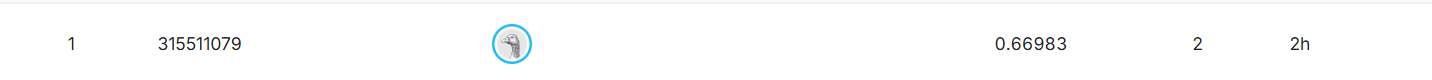